In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
from google.colab import files

uploaded = files.upload()

df = pd.read_csv('googleplaystore.csv')

print("Dataset loaded successfully!")
print(df.head())

Saving googleplaystore.csv to googleplaystore (1).csv
Dataset loaded successfully!
                                                 App        Category  Rating  \
0     Photo Editor & Candy Camera & Grid & ScrapBook  ART_AND_DESIGN     4.1   
1                                Coloring book moana  ART_AND_DESIGN     3.9   
2  U Launcher Lite – FREE Live Cool Themes, Hide ...  ART_AND_DESIGN     4.7   
3                              Sketch - Draw & Paint  ART_AND_DESIGN     4.5   
4              Pixel Draw - Number Art Coloring Book  ART_AND_DESIGN     4.3   

  Reviews  Size     Installs  Type Price Content Rating  \
0     159   19M      10,000+  Free     0       Everyone   
1     967   14M     500,000+  Free     0       Everyone   
2   87510  8.7M   5,000,000+  Free     0       Everyone   
3  215644   25M  50,000,000+  Free     0           Teen   
4     967  2.8M     100,000+  Free     0       Everyone   

                      Genres      Last Updated         Current Ver  \
0          

In [ ]:
print("Dataset Shape:", df.shape)

print("\nColumn Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nStatistical Summary:")
print(df.describe())

Dataset Shape: (10841, 13)

Column Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10841 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             10841 non-null  object 
 1   Category        10841 non-null  object 
 2   Rating          9367 non-null   float64
 3   Reviews         10841 non-null  object 
 4   Size            10841 non-null  object 
 5   Installs        10841 non-null  object 
 6   Type            10840 non-null  object 
 7   Price           10841 non-null  object 
 8   Content Rating  10840 non-null  object 
 9   Genres          10841 non-null  object 
 10  Last Updated    10841 non-null  object 
 11  Current Ver     10833 non-null  object 
 12  Android Ver     10838 non-null  object 
dtypes: float64(1), object(12)
memory usage: 1.1+ MB
None

Missing Values:
App                  0
Category             0
Rating            1474
Reviews              0
S

In [ ]:
# Remove duplicate records
df = df.drop_duplicates()

# Fill missing values in Rating
df['Rating'] = df['Rating'].fillna(df['Rating'].median())

# Fill missing values in Reviews
df['Reviews'] = df['Reviews'].fillna(0)

# Remove rows with missing values
df = df.dropna()

print("Data Cleaning Completed!")

print("Remaining Missing Values:")
print(df.isnull().sum())

Data Cleaning Completed!
Remaining Missing Values:
App               0
Category          0
Rating            0
Reviews           0
Size              0
Installs          0
Type              0
Price             0
Content Rating    0
Genres            0
Last Updated      0
Current Ver       0
Android Ver       0
dtype: int64


In [ ]:
# Convert Installs and Price into numbers
df['Installs'] = pd.to_numeric(
    df['Installs'].str.replace(r'[,+]', '', regex=True), errors='coerce'
).fillna(0)

df['Price'] = pd.to_numeric(
    df['Price'].str.replace('$', '', regex=False), errors='coerce'
).fillna(0)

# Identify Free and Paid apps
df['App_Type'] = np.where(df['Price'] == 0, 'Free', 'Paid')

# Display results
print(df[['App', 'Installs', 'Price', 'App_Type']].head())

                                                 App  Installs  Price App_Type
0     Photo Editor & Candy Camera & Grid & ScrapBook     10000    0.0     Free
1                                Coloring book moana    500000    0.0     Free
2  U Launcher Lite – FREE Live Cool Themes, Hide ...   5000000    0.0     Free
3                              Sketch - Draw & Paint  50000000    0.0     Free
4              Pixel Draw - Number Art Coloring Book    100000    0.0     Free


In [ ]:
# Convert Reviews to numeric type first
df['Reviews'] = pd.to_numeric(df['Reviews'], errors='coerce').fillna(0).astype(int)

# Find outliers using IQR
Q1 = df['Reviews'].quantile(0.25)
Q3 = df['Reviews'].quantile(0.75)

IQR = Q3 - Q1

# Find and count outliers
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

print("Number of outliers:", len(df[(df['Reviews'] < lower) | (df['Reviews'] > upper)]))

# Cap outliers
df['Reviews_Capped'] = df['Reviews'].clip(lower, upper)

print("Outlier handling completed!")

Number of outliers: 1868
Outlier handling completed!


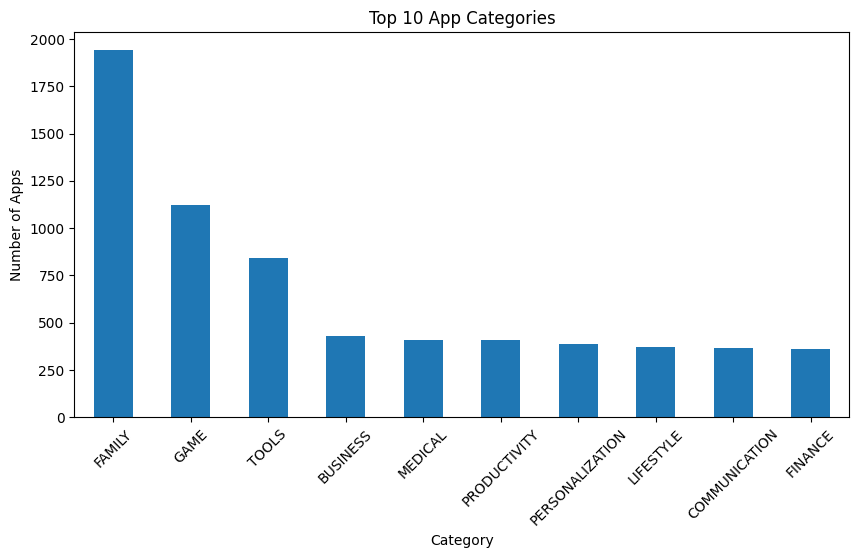

In [ ]:
top_categories = df['Category'].value_counts().head(10)

top_categories.plot(kind='bar', figsize=(10,5))

plt.title('Top 10 App Categories')
plt.xlabel('Category')
plt.ylabel('Number of Apps')
plt.xticks(rotation=45)
plt.show()

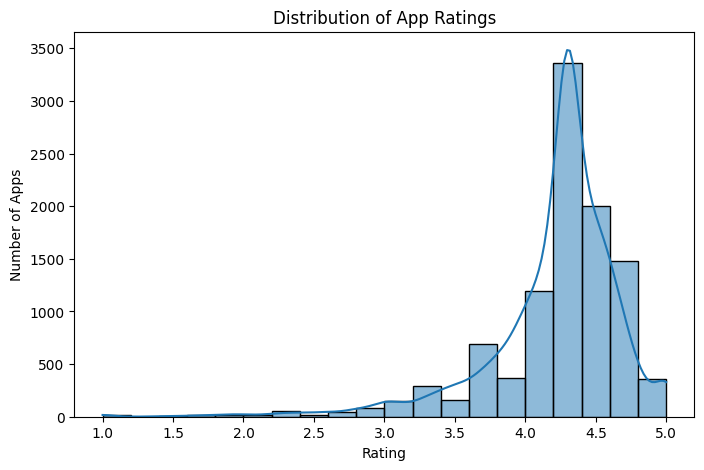

In [ ]:
plt.figure(figsize=(8,5))

sns.histplot(df['Rating'], bins=20, kde=True)

plt.title('Distribution of App Ratings')
plt.xlabel('Rating')
plt.ylabel('Number of Apps')

plt.show()